# Example 4: ice loss by sublimation and photosputtering

A disk of icy grains (3–200 au; astronomical silicate with 50 % crystalline water ice by volume,
Kim et al. 2019) around a solar-type star at 10 pc. Grains lose their ice in two ways, and the ice-free
remainder is porous silicate (component 2):

* **sublimation** where they are warmer than 110 K (`sublimation`, Sect. 6.3 of the manual);
* **photosputtering** (`photosputtering`, DMS 2.2, Sect. 6.4): UV photons (5.1–13.6 eV) remove
  water molecules, about one per 1000 absorbed photons (Grigorieva et al. 2007). The ice of a grain
  of radius a is gone after t_ps = 4 ρ_w a / (m_H₂O Y N_abs), which grows with a and with the
  distance (N_abs ∝ r⁻²). A grain loses its ice where t_ps is shorter than the time it has left at
  that place: its collisional lifetime, the Poynting–Robertson (P-R) drag time, or the age.

Four models of the same disk:

| model | ice loss | reference time |
|---|---|---|
| `subl` | sublimation only | – |
| `ps` | + photosputtering | shortest of collisions (vertical optical depth of `subl`) and P-R drag |
| `ps_release` | as `ps`, UV and P-R time of the orbit after release (`ps_orbit = 'release'`) | same |
| `ps_pr` | + photosputtering | P-R drag only (the limit of a faint disk) |

A second part takes an eccentric belt, where the ice of a grain depends on its orbit rather than on
its momentary distance from the star (`ps_orbit = 'release'` with orbit bins).

The SEDs (0.4–1000 µm) show what the ice loss does to the scattered light and the thermal emission.
DMS decides which grains keep their ice; it does not move grains (P-R drag enters as a time scale)
and does not follow their erosion in time. The stellar UV here is that of a 5770 K black body; for
measured spectra (chromospheric UV of K and M stars) use `ps_uv_file`. The run takes about a minute.

In [1]:
# Setup: this notebook lives in the examples/ folder of the repository
import os, sys
REPO = os.environ.get("DMS_REPO") or os.path.abspath("..")
sys.path.insert(0, os.path.join(REPO, "python"))      # use the DMS of this repository
import dms
import numpy as np
import matplotlib.pyplot as plt
print("DMS", dms.__version__, "from", os.path.relpath(os.path.dirname(dms.__file__), REPO))

DMS 2.2.0 from python/dms


## The disk

Component 1 is the icy mixture, component 2 the porous silicate left behind (abundance 0: it only
forms by losing ice). By volume the mixture is 0.5 × 3.5 + 0.5 × 1.0 = 2.25 g/cm³, so the ice is
0.5 / 2.25 = 22 % of its mass (`ps_ice_fraction`). The yield Y = 10⁻³ is that of Grigorieva et
al. (2007). The Mie results are kept in `cache/` and shared by all four models.

In [2]:
ICE_FRACTION = 0.5 * 1.0 / (0.5 * 3.5 + 0.5 * 1.0)      # ice mass fraction of the mixture

disk = dms.Model(
    run={"mode": "sed", "emission": "both", "load_optics": True, "save_optics": True,
         "optics_cache_name": "example4"},
    star={"teff": 5770.0, "radius": 1.0, "mass": 1.0, "distance": 10.0},
    disk={"density_law": "powerlaw", "alpha": 1.0, "r_in": 3.0, "r_out": 200.0,
          "opening_angle": 5.0, "dust_mass": 1e-7, "inclination": 0.0},
    wavelengths={"lambda_min": 0.4, "lambda_max": 1000.0, "n_lambda": 60},
    dust={"n_components": 2,
          "optical_data": ["kim2019/ice_astrosilicate_MG/Sil50cice50",
                           "kim2019/porous_astrosilicate/as50vac50"],
          "bulk_density": [2.25, 1.75], "abundance": [1.0, 0.0],
          "a_min": 0.1, "a_max": 1000.0, "q": 3.5, "n_sizes": 120, "blowout": True,
          "sublimation": True, "t_sublimation": [110.0, -1.0], "sublimation_residue": [2, 0]},
)
PS = {"photosputtering": True, "ps_yield": [1e-3, 0.0], "ps_ice_fraction": [ICE_FRACTION, 1.0],
      "ps_residue": [2, 0]}

## Four runs

The collisional lifetime needs the vertical optical depth of the disk; it is taken from the first
run (`tau_peak`, the largest azimuthally averaged value; a larger optical depth means a shorter
collisional lifetime, so more grains are destroyed before they lose their ice).

In [3]:
res = {"subl": disk.copy().run()}
tau = res["subl"].tau_peak
print(f"vertical optical depth: peak {tau:.2e}, mean {res['subl'].tau_mean:.2e}")

res["ps"] = disk.copy().update(dust={**PS, "ps_time": "shortest", "ps_tau": tau}).run()
res["ps_release"] = disk.copy().update(dust={**PS, "ps_time": "shortest", "ps_tau": tau,
                                             "ps_orbit": "release"}).run()
res["ps_pr"] = disk.copy().update(dust={**PS, "ps_time": "pr"}).run()

vertical optical depth: peak 1.96e-03, mean 1.02e-03


## Where the grains lose their ice

`res.photosputtering["r_ice_loss"][size, component]` is the largest distance [au] at which grains of
that size lose their ice by photosputtering (0: nowhere; the outer edge, 200 au: everywhere). The
sublimation radius of each size is where its temperature reaches 110 K.

In [4]:
a = res["subl"].grains["a"]
beta = res["subl"].grains["beta"][:, 0]
T = res["subl"].temperature                     # T["T"][distance, component, size]
r_subl = np.array([T["r_au"][T["T"][:, 0, i] >= 110.0].max() if (T["T"][:, 0, i] >= 110.0).any() else 0.0
                   for i in range(len(a))])
bound = beta < 0.5
print(f"UV photons (5.1-13.6 eV) at 1 au: {res['ps'].photosputtering['photons_1au']:.2e} per cm^2 and s")
print(f"smallest bound grain: {a[bound].min():.2f} micron (beta = {beta[bound][0]:.2f})")
print(f"{'a [um]':>8s} {'beta':>6s} {'sublimation':>12s} {'ps':>6s} {'release':>8s} {'P-R only':>9s}   [au]")
for i in range(0, len(a), 6):
    if not bound[i]:
        continue
    row = [res[k].photosputtering["r_ice_loss"][i, 0] for k in ("ps", "ps_release", "ps_pr")]
    print(f"{a[i]:8.3g} {beta[i]:6.3f} {r_subl[i]:12.1f} {row[0]:6.0f} {row[1]:8.0f} {row[2]:9.0f}")

UV photons (5.1-13.6 eV) at 1 au: 1.18e+15 per cm^2 and s
smallest bound grain: 0.56 micron (beta = 0.48)
  a [um]   beta  sublimation     ps  release  P-R only   [au]
   0.656  0.411         12.8    200      200       200
    1.04  0.252         11.6    200      200       200
    1.65  0.153         10.0    200      200       200
    2.61  0.096          8.2     94       61       200
    4.14  0.061          6.7      6        5       200
    6.56  0.039          5.7      0        0       200
    10.4  0.025          5.3      0        0       200
    16.5  0.016          5.2      0        0       200
    26.1  0.010          5.4      5        5       200
    41.4  0.006          5.6     25       24       200
    65.6  0.004          5.9     43       42       200
     104  0.002          6.1     23       22       200
     165  0.001          6.3     12       12       200
     261  0.001          6.4      6        6       200
     414  0.001          6.5      3        3       200
     65

## Summary

In [5]:
rho = np.array([2.25, 1.75])                               # bulk densities of the two components
for k, r in res.items():
    m = (r.grains["number"] * a[:, None]**3 * rho).sum(axis=0)    # dust mass per component (relative)
    n = r.grains["number"].sum(axis=0)
    print(f"{k:11s}  f_d = {r.f_d:.2e}   icy grains: {100 * n[0] / n.sum():5.1f} % by number, "
          f"{100 * m[0] / m.sum():5.1f} % by mass")

subl         f_d = 1.53e-03   icy grains:  83.9 % by number,  99.9 % by mass
ps           f_d = 1.50e-03   icy grains:   1.9 % by number,  97.4 % by mass
ps_release   f_d = 1.50e-03   icy grains:   2.3 % by number,  97.6 % by mass
ps_pr        f_d = 1.92e-03   icy grains:   0.0 % by number,   0.0 % by mass


## Figure

Left: the ice-loss radius against grain size (shaded: grains below the blow-out size, removed as they
are). The smallest bound grains lose their ice everywhere: their sputtering time is shorter than
every reference time. Larger grains keep it outside a few to a few tens of au, because collisions
destroy them first; the steps follow the size dependence of the collisional lifetime (shortest just
above the blow-out size and above about 100 times it). With P-R drag alone (a faint disk) every size
loses its ice everywhere. `ps_release` differs from `ps` only for small grains, which spend most of
their time on wide orbits.

Middle and right: the SEDs and their ratio to `subl`. The dust mass refers to the dust that is left,
so grains that lost their ice are lighter and more numerous; this sets the overall level of the
thermal emission with P-R drag only. The scattered light (dotted) comes mostly from the small grains:
it changes by 10–40 % below 2 µm, and the 3 µm ice band disappears.

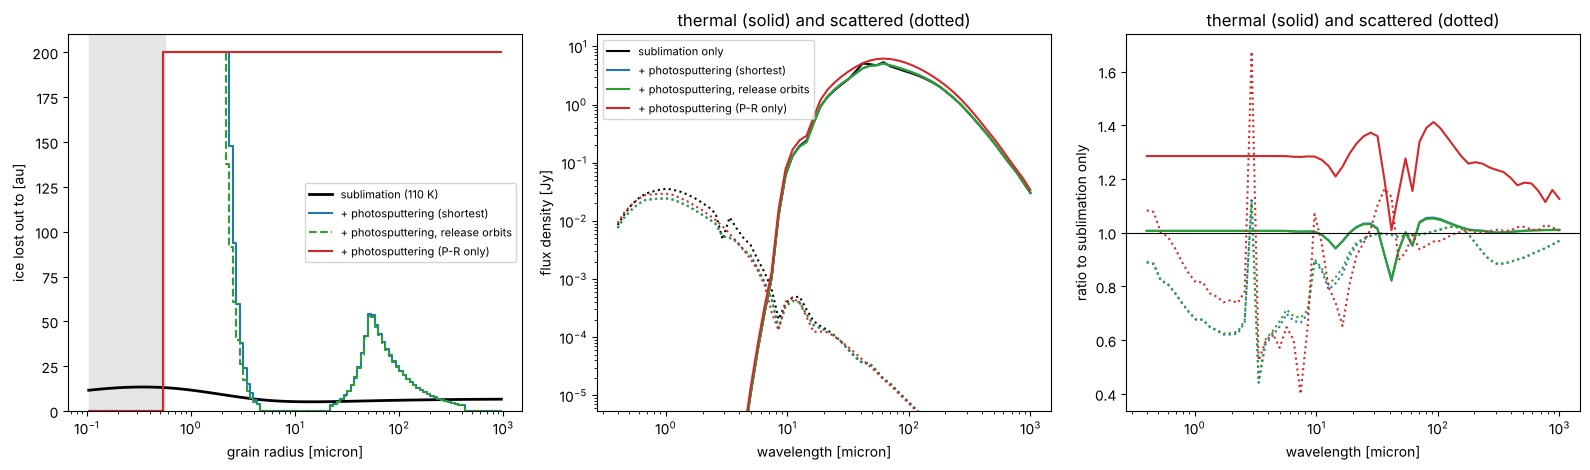

In [6]:
colours = {"ps": "C0", "ps_release": "C2", "ps_pr": "C3"}
labels = {"subl": "sublimation only", "ps": "+ photosputtering (shortest)",
          "ps_release": "+ photosputtering, release orbits", "ps_pr": "+ photosputtering (P-R only)"}
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))

ax[0].semilogx(a, r_subl, "k-", lw=2, label="sublimation (110 K)")
for k in ("ps", "ps_release", "ps_pr"):
    ax[0].semilogx(a, res[k].photosputtering["r_ice_loss"][:, 0], drawstyle="steps-mid",
                   color=colours[k], ls="--" if k == "ps_release" else "-", label=labels[k])
ax[0].axvspan(a[0], a[bound].min(), color="0.9", zorder=0)
ax[0].set_xlabel("grain radius [micron]")
ax[0].set_ylabel("ice lost out to [au]")
ax[0].set_ylim(0, 210)
ax[0].legend(fontsize=8)

lam = res["subl"].wavelength
for k, r in res.items():
    c = colours.get(k, "k")
    ax[1].loglog(lam, r.sed["scattered"], color=c, ls=":")
    ax[1].loglog(lam, r.sed["thermal"], color=c, label=labels[k])
    if k != "subl":
        ax[2].semilogx(lam, r.sed["scattered"] / res["subl"].sed["scattered"], color=c, ls=":")
        ax[2].semilogx(lam, r.sed["thermal"] / res["subl"].sed["thermal"], color=c, label=labels[k])
ax[1].set_ylim(1e-6 * res["subl"].sed["thermal"].max(), 3 * res["subl"].sed["thermal"].max())
ax[1].set_xlabel("wavelength [micron]"); ax[1].set_ylabel("flux density [Jy]")
ax[1].set_title("thermal (solid) and scattered (dotted)")
ax[1].legend(fontsize=8)
ax[2].axhline(1.0, color="k", lw=0.8)
ax[2].set_xlabel("wavelength [micron]"); ax[2].set_ylabel("ratio to sublimation only")
ax[2].set_title("thermal (solid) and scattered (dotted)")
plt.tight_layout()
plt.savefig("example4_ice_loss.png", dpi=120)
plt.show()

## An eccentric belt: ice state per orbit

In an eccentric belt the dust at one distance from the star belongs to different orbits: on the
pericentre side to orbits of larger semi-major axis than on the apocentre side. Photosputtering acts
over many orbits, so whether a grain keeps its ice depends on the UV averaged over its orbit.

* `ps_orbit = 'local'`: the ice is decided at every point from the UV there (as for a circular belt).
* `ps_orbit = 'release'`: DMS divides each eccentric belt into `ps_orbit_bins` bins in semi-major
  axis (default 32) and decides the ice per orbit, from the UV and the P-R time of the orbit each
  grain follows after its release (here at the pericentre of its parent orbit, `blowout_release`).
  A point of the belt takes the population of its orbit; temperatures, sublimation and blow-out stay
  functions of the distance.

A belt with semi-major axes 30–60 au and e = 0.3 (pericentre at the top of the image, the star at
the origin), face-on; the ice of a grain is lost if it is sputtered within 10⁵ yr
(`ps_time = 'age'`). The maps show the ratio of the scattered light at 3.1 µm (water-ice band) to
2.0 µm, which changes with the grain population. With `'local'` its contours are circles around the
star (the population is set by the distance); with `'release'` they follow the orbits of the belt.

In [7]:
ecc = dms.Model(
    run={"mode": "both", "emission": "both", "load_optics": True, "save_optics": True,
         "optics_cache_name": "example4"},
    star=disk.params["star"],
    disk={"density_law": "powerlaw", "alpha": 1.0, "r_in": 30.0, "r_out": 60.0,
          "eccentricity": 0.3, "omega": 0.0, "opening_angle": 5.0, "dust_mass": 1e-7,
          "inclination": 0.0},
    image={"n_pixels": 101, "n_split_max": 2},
    wavelengths={"lambda": [2.0, 3.1]},
    dust={**disk.params["dust"], "blowout_release": "pericentre", **PS,
          "ps_time": "age", "ps_age": 1e5},
)
ecc_res = {orbit: ecc.copy().update(dust={"ps_orbit": orbit}).run() for orbit in ("local", "release")}

ps = ecc_res["release"].photosputtering
print(f"{ps['orbit_bins']} orbit bins")
print(f"{'a [um]':>8s} {'local: distance':>16s} {'release: semi-major axis':>25s}   [au]")
bound_peri = ecc_res["release"].grains["beta"][:, 0] < (1 - 0.3) / 2     # bound after release at pericentre
for i in range(0, len(a), 12):
    if bound_peri[i]:
        print(f"{a[i]:8.3g} {ecc_res['local'].photosputtering['r_ice_loss'][i, 0]:16.1f} "
              f"{ps['a_ice_loss'][i, 0]:25.1f}")

32 orbit bins
  a [um]  local: distance  release: semi-major axis   [au]
    1.65             78.0                      59.4
    4.14             78.0                      59.4
    10.4             78.0                      59.4
    26.1             78.0                      59.4
    65.6             78.0                      59.4
     165             54.9                      55.6
     414             34.6                      35.3


The ice-loss limits above are the largest distance (`'local'`) and the largest semi-major axis
(`'release'`, `res.photosputtering["a_ice_loss"]`) at which grains of that size lose their ice;
78 au (the outer edge of the distance grid) and 59 au (the centre of the outermost orbit bin) mean
everywhere. The orbits of semi-major axis a reach from a(1 − e) to a(1 + e), so the two columns
differ for the large grains, which keep their ice on the outer orbits.

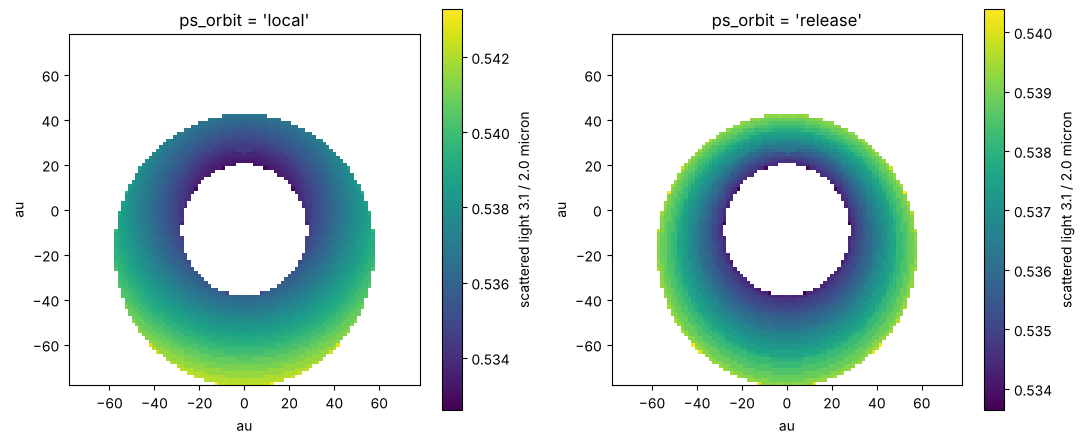

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
for j, orbit in enumerate(("local", "release")):
    img = ecc_res[orbit].image("scattered")             # [wavelength, y, x]
    with np.errstate(divide="ignore", invalid="ignore"):
        ratio = img[1] / img[0]
    ratio[img[0] < 1e-3 * img[0].max()] = np.nan
    half = ecc_res[orbit].pixel_au * img.shape[-1] / 2
    p = ax[j].imshow(ratio, origin="lower", cmap="viridis", extent=[-half, half, -half, half])
    ax[j].set_title(f"ps_orbit = '{orbit}'")
    ax[j].set_xlabel("au"); ax[j].set_ylabel("au")
    plt.colorbar(p, ax=ax[j], label="scattered light 3.1 / 2.0 micron")
plt.tight_layout()
plt.savefig("example4_eccentric.png", dpi=120)
plt.show()